# Laboratory 3 — Cleaning a Noisy ECG

**CN240 Data Science for Signal Processing · SF251 Introduction to Data Science**
Week 3 · Semester 1, Academic Year 2026 · Dr Surasak Phetmanee

---

| | |
|---|---|
| **Name** | *Ruth Benedicta Susanto* |
| **Student ID** | *6710755239* |
| **Section** | *750001* |

## What you will do today

Week 2's ECG returns — but this time it has been **deliberately damaged**: dropouts (NaN), electrode-pop
spikes, and baseline wander. You will diagnose the damage, treat it with the week-3 recipe, and **prove**
your treatment worked.

**The recipe (order matters — lecture slide 14):**
`inspect → repair holes → kill spikes → smooth → normalise → verify`

**Deliverables (due before week 4, pushed to your GitHub repository):**
1. This notebook, fully run — the whole recipe applied
2. The **decisions table** — every constant you chose, defended in one sentence
3. **SNR before vs after** — one number that proves the cleaning helped

> **Guardrail:** the QRS peaks must survive. Over-smoothing that flattens the heartbeats fails the lab.


## Setup — run these two cells first, do not edit

The second cell loads the week-2 ECG and injects the damage. It also keeps `clean_reference` —
the undamaged original — so that at the end you can measure how close your repair came.
*(Deterministic seed: everyone gets the same damage.)*


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import medfilt

plt.rcParams['figure.figsize'] = (12, 3.5)
plt.rcParams['axes.grid'] = True
print("NumPy", np.__version__, "· Pandas", pd.__version__)

NumPy 2.4.6 · Pandas 2.2.3


In [16]:
# --- Lab data setup: load ECG and damage it (run once, do not edit) ----------
FS = 360                                        # sampling rate, Hz
rng = np.random.default_rng(240)

try:                                            # real 5-minute MIT-BIH excerpt
    from scipy.datasets import electrocardiogram
    clean_reference = electrocardiogram()[:60 * FS]          # first 60 s
    SOURCE = "MIT-BIH (real recording)"
except Exception:                               # offline fallback: synthetic ECG
    t = np.arange(0, 60, 1 / FS)
    beat = 1.1 * np.exp(-((t % 0.85) - 0.28) ** 2 / 0.0009)
    clean_reference = (beat - 0.25 * np.exp(-((t % 0.85) - 0.38) ** 2 / 0.004)
                       + 0.03 * rng.standard_normal(t.size))
    SOURCE = "synthetic (offline fallback)"

n = clean_reference.size
t = np.arange(n) / FS
dirty = clean_reference.copy()

# 1) baseline wander — slow 0.25 Hz drift (breathing / loose electrode)
dirty += 0.35 * np.sin(2 * np.pi * 0.25 * t)

# 2) electrode-pop spikes — 40 impulses of ±3–5 mV
spike_idx = rng.choice(n, size=40, replace=False)
dirty[spike_idx] += rng.choice([-1, 1], 40) * rng.uniform(3, 5, 40)

# 3) dropouts — 25 gaps of 5–60 samples become NaN
for start in rng.choice(n - 80, size=25, replace=False):
    dirty[start : start + rng.integers(5, 60)] = np.nan

dirty = pd.Series(dirty)
print(f"ecg loaded from {SOURCE}: {n} samples = {n/FS:.0f} s at {FS} Hz")
print(f"damage injected: {dirty.isna().sum()} NaN samples, 40 spikes, baseline wander")

ecg loaded from MIT-BIH (real recording): 21600 samples = 60 s at 360 Hz
damage injected: 940 NaN samples, 40 spikes, baseline wander


---
## Task 1 — Diagnose *(worked example: read it, then run it)*

Never treat before you diagnose. Count the holes, look at the damage, and know your enemy.


NaN count   : 940
NaN fraction: 4.35%   (small fraction -> interpolation is honest)


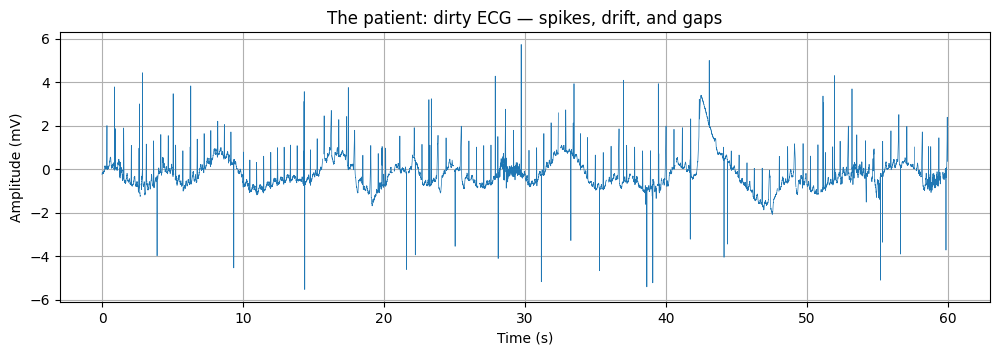

In [17]:
print("NaN count   :", dirty.isna().sum())
print("NaN fraction:", f"{dirty.isna().mean():.2%}   (small fraction -> interpolation is honest)")

plt.plot(t, dirty, linewidth=0.5)
plt.xlabel("Time (s)"); plt.ylabel("Amplitude (mV)")
plt.title("The patient: dirty ECG — spikes, drift, and gaps")
plt.show()

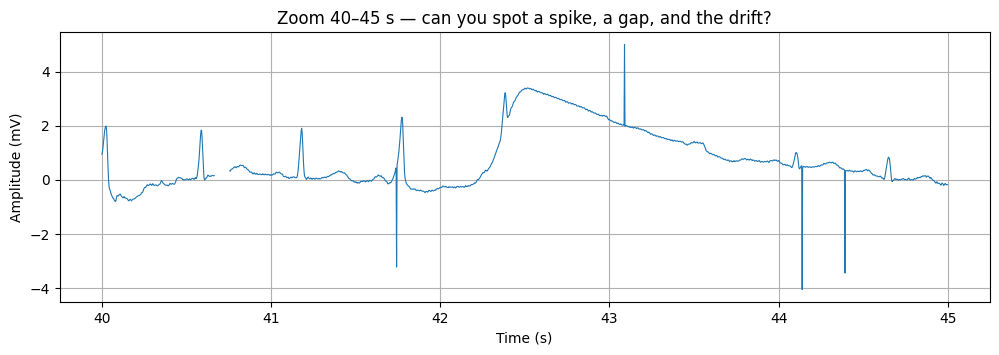

In [18]:
# Zoom into 5 seconds so the three kinds of damage are visible individually
start, stop = 40, 45
sl = slice(int(start * FS), int(stop * FS))
plt.plot(t[sl], dirty[sl], linewidth=0.8)
plt.xlabel("Time (s)"); plt.ylabel("Amplitude (mV)")
plt.title(f"Zoom {start}–{stop} s — can you spot a spike, a gap, and the drift?")
plt.show()

**Q1 — from the two plots:** identify one example of each damage type (give the approximate time in
seconds): a dropout, a spike, and the baseline wander.

*Around 40.6–40.7 s there is a gap. Spike exists around 14.3 s. From 10 - 13 s the amplitude is rises and falls indicate baseline wander.*


---
## Task 2 — Choose your constants

These three numbers **are** the lab. Choose them now, refine them as you see results, and defend each
one in the decisions table at the end. The lecture gave you the reasoning tools:

- `LIMIT_MS` — the longest gap you are willing to bridge by interpolation *(slide 6: bridge 50 ms honestly, never 5 s)*
- `KERNEL` — median filter width in samples, **must be odd** *(slide 13: just wide enough to swallow a 1-sample spike)*
- `WINDOW` — moving-average width in samples *(slide 12: well under the QRS width ≈ 80 ms × fs)*


In [19]:
# TODO: replace None with your chosen values
LIMIT_MS = 50      # e.g. somewhere between 20 and 100 (milliseconds)
KERNEL   = 5      # odd number, e.g. 3–9 (samples)
WINDOW   = 5
FS = 360   # e.g. 5–25 (samples) — remember the QRS guardrail!

if None in (LIMIT_MS, KERNEL, WINDOW):
    print("choose your three constants above before continuing")
else:
    print(f"limit = {LIMIT_MS} ms = {int(LIMIT_MS/1000*FS)} samples | "
          f"kernel = {KERNEL} | window = {WINDOW}")
    assert KERNEL % 2 == 1, "median filter kernel must be odd!"

limit = 50 ms = 18 samples | kernel = 5 | window = 5


---
## Task 3 — Treat, one step at a time

Apply the recipe **in order**. After each step, the plot shows what that step changed — look at it
before moving on.


NaN before: 940
NaN after capped interpolation: 514
Longer gaps remain NaN rather than being silently forward/backward-filled.


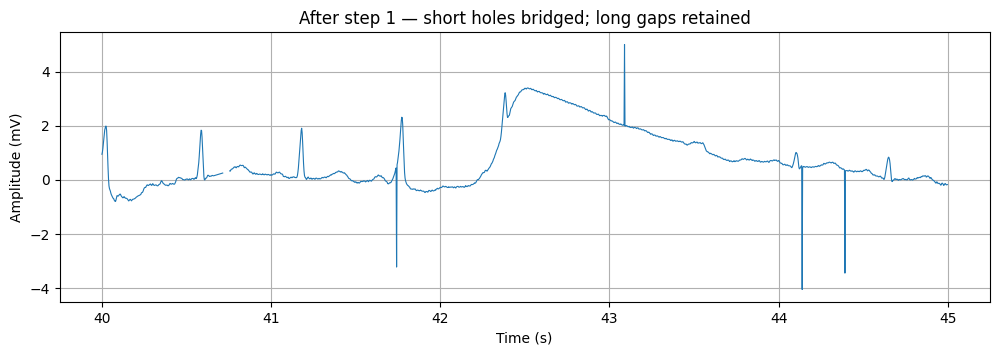

In [20]:
# Step 1 — repair the holes (linear interpolation, capped)
limit_samples = int(round(LIMIT_MS / 1000 * FS))
step1 = dirty.interpolate(
    method="linear",
    limit=limit_samples,
    limit_direction="forward",
    limit_area="inside"
)

print("NaN before:", dirty.isna().sum())
print("NaN after capped interpolation:", step1.isna().sum())
print("Longer gaps remain NaN rather than being silently forward/backward-filled.")

# Helper: apply a filter separately to each contiguous finite segment.
# This prevents filters from treating missing sections as real ECG values.
def apply_to_finite_runs(series, operation):
    values = np.asarray(series, dtype=float)
    result = np.full(values.shape, np.nan, dtype=float)
    finite = np.isfinite(values)

    edges = np.diff(np.r_[False, finite, False].astype(int))
    starts = np.where(edges == 1)[0]
    stops = np.where(edges == -1)[0]

    for start, stop in zip(starts, stops):
        segment = pd.Series(values[start:stop])
        result[start:stop] = operation(segment).to_numpy(dtype=float)

    return pd.Series(result, index=series.index)

plt.plot(t[sl], step1.iloc[sl], linewidth=0.8)
plt.title("After step 1 — short holes bridged; long gaps retained")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (mV)")
plt.show()


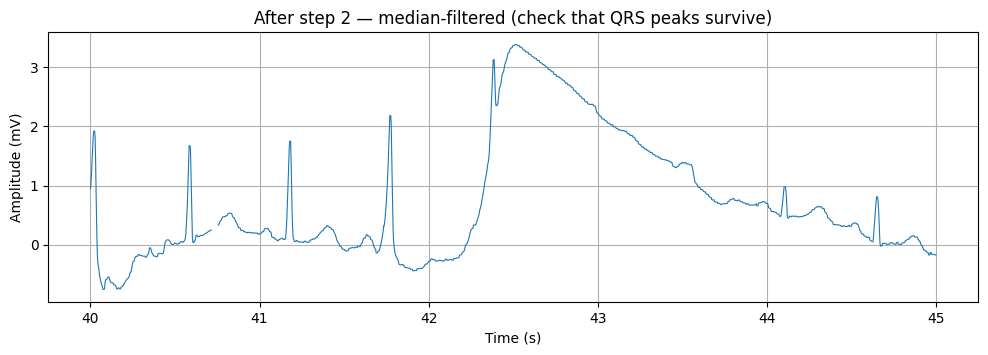

In [21]:
# Step 2 — kill the spikes (median filter)
step2 = apply_to_finite_runs(
    step1,
    lambda segment: segment.rolling(
        window=KERNEL, center=True, min_periods=1
    ).median()
)

plt.plot(t[sl], step2.iloc[sl], linewidth=0.8)
plt.title("After step 2 — median-filtered (check that QRS peaks survive)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (mV)")
plt.show()


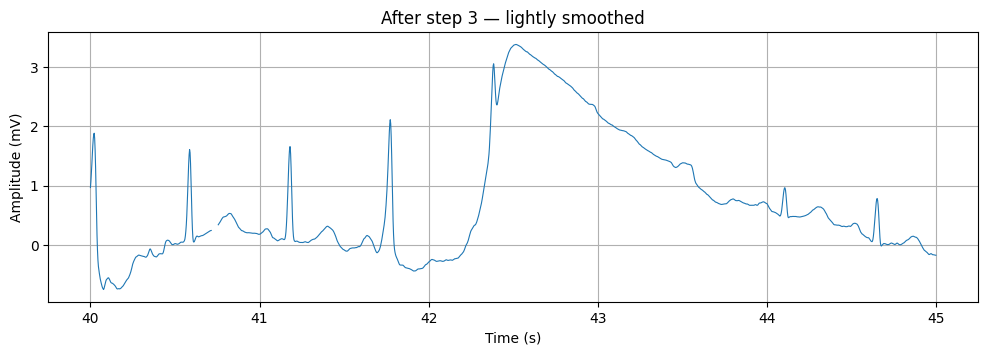

In [22]:
# Step 3 — smooth the residual noise (moving average)
step3 = apply_to_finite_runs(
    step2,
    lambda segment: segment.rolling(
        window=WINDOW, center=True, min_periods=1
    ).mean()
)

plt.plot(t[sl], step3.iloc[sl], linewidth=0.8)
plt.title("After step 3 — lightly smoothed")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (mV)")
plt.show()


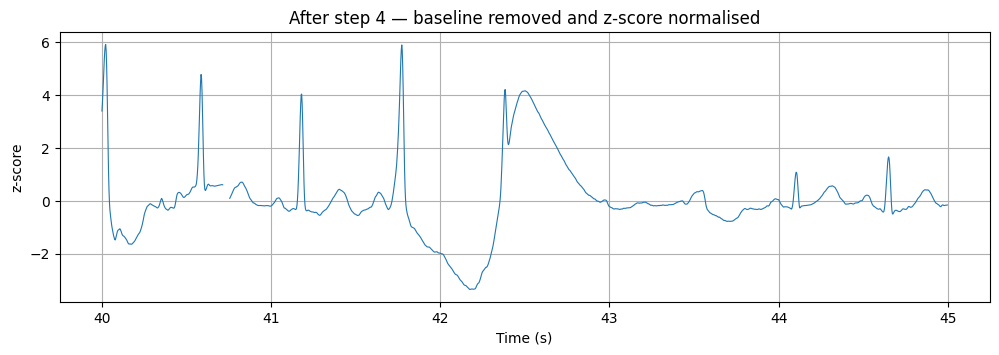

In [26]:
# Step 4 — remove the baseline wander, then z-score normalise
# The wander is a very slow trend: estimate it with a LONG moving average (~1 s), subtract it.
baseline = apply_to_finite_runs(
    step3,
    lambda segment: segment.rolling(
        window=FS, center=True, min_periods=1
    ).mean()
)
detrended = step3 - baseline

valid = detrended.notna()
cleaned = pd.Series(np.nan, index=detrended.index, dtype=float)
cleaned.loc[valid] = (
    detrended.loc[valid] - detrended.loc[valid].mean()
) / detrended.loc[valid].std()

plt.plot(t[sl], cleaned.iloc[sl], linewidth=0.8)
plt.title("After step 4 — baseline removed and z-score normalised")
plt.xlabel("Time (s)")
plt.ylabel("z-score")
plt.show()


**Q2 — the long window paradox:** in step 4 we used a moving average with a *huge* window (1 second)
— exactly what slide 12 warned would destroy the QRS. Why is it the right tool *here*? What are we
keeping, and what are we throwing away?

*Baseline wander is a slow change, huge window is suitable. we keep the slow baseline trend, like QRS that not part of baseline estimate, we throw rapid ECG component.*


---
## Task 4 — Prove it

Three pieces of evidence: the before/after picture, the SNR number (your week-2 estimator), and —
because this lab kept the undamaged original — the correlation with the truth.


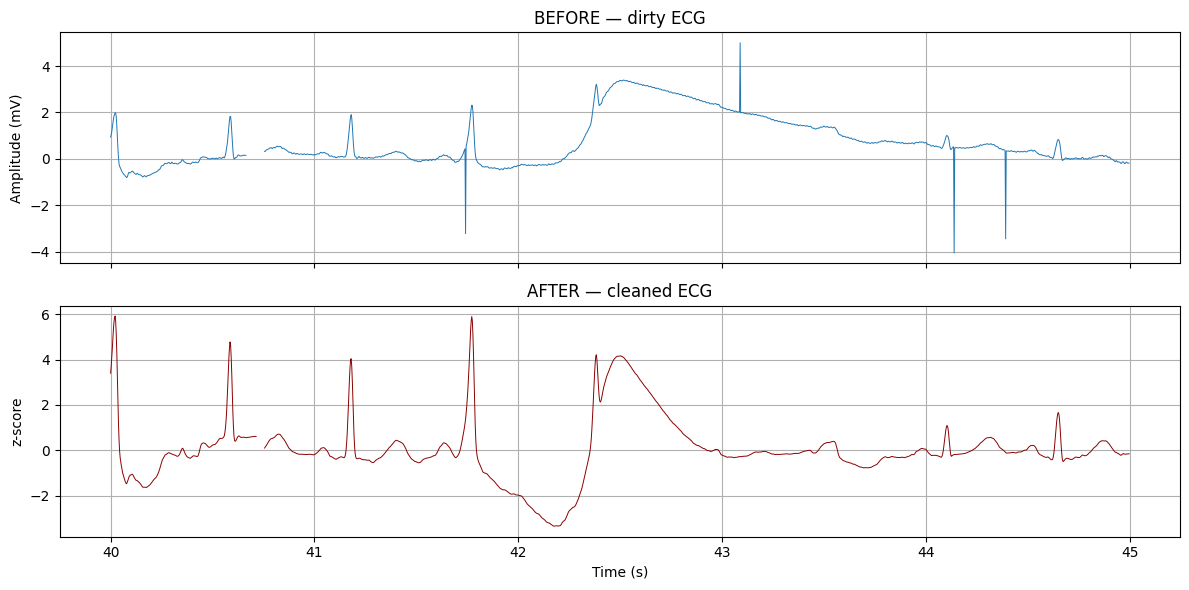

SNR before :   11.9 dB
SNR after  :   19.2 dB
Correlation with undamaged original (valid samples only): r = 0.584
Samples retained for comparison: 21086 / 21600


In [27]:
def snr_db(x):
    """Week 2 quick SNR estimate; ignore differences that cross NaN gaps."""
    x = np.asarray(x, dtype=float)
    finite = np.isfinite(x)
    signal_values = x[finite]

    adjacent_valid = finite[:-1] & finite[1:]
    noise = np.diff(x)[adjacent_valid] / np.sqrt(2)

    if signal_values.size < 2 or noise.size < 2:
        return np.nan
    noise_variance = np.var(noise)
    if noise_variance == 0:
        return np.inf
    return 10 * np.log10(np.var(signal_values) / noise_variance)

ref = (clean_reference - clean_reference.mean()) / clean_reference.std()
valid = np.isfinite(cleaned.to_numpy())
r = np.corrcoef(cleaned.to_numpy()[valid], ref[valid])[0, 1]

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(t[sl], dirty.iloc[sl], linewidth=0.7)
axes[0].set_title("BEFORE — dirty ECG")
axes[0].set_ylabel("Amplitude (mV)")
axes[1].plot(t[sl], cleaned.iloc[sl], linewidth=0.7, color="darkred")
axes[1].set_title("AFTER — cleaned ECG")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("z-score")
plt.tight_layout()
plt.show()

print(f"SNR before : {snr_db(dirty):6.1f} dB")
print(f"SNR after  : {snr_db(cleaned):6.1f} dB")
print(f"Correlation with undamaged original (valid samples only): r = {r:.3f}")
print(f"Samples retained for comparison: {valid.sum()} / {len(cleaned)}")


**Q3 — interpret your evidence:** did SNR improve, and is the correlation high? If you push `WINDOW`
up to 101, what happens to the correlation — and why does that match the lecture's over-smoothing
warning? *(Try it, then put your constants back.)*

*when window increase to 101, the ECG is tooo smooth, and can preserve QRS clearly. At 500 Hz the correlation between the undamaged decrease [with 202 ms] suppose to be not more than 80 ms.*


---
## Task 5 — The decisions table *(deliverable 2)*

| Constant | Your value | One-sentence defence |
|---|---|---|
| `LIMIT_MS` | 50| inside the range|
| `KERNEL` | 5 | inside the range |
| `WINDOW` | 5 | will create sample under 80ms |

*A defence names the trade-off: e.g. “50 ms bridges electrode dropouts but refuses to invent whole
heartbeats.”*


---
## Bonus (optional) — beat the reference pipeline

Can you push the correlation higher? Ideas: detrend **before** the median filter; try a
`medfilt` second pass; tune the windows. Record your best `r` and what changed it.


In [25]:
# Bonus playground — copy the pipeline here and experiment
from scipy.signal import butter, filtfilt

LIMIT_MS, KERNEL, WINDOW = 170, 3, 5

s1 = dirty.interpolate(method="linear", limit=int(LIMIT_MS/1000*FS)).ffill().bfill()
s2 = pd.Series(medfilt(s1, kernel_size=KERNEL))
s3 = s2.rolling(WINDOW, center=True, min_periods=1).mean()

b, a = butter(2, 0.5 / (FS/2), btype="high")      # 0.5 Hz high-pass
detr = pd.Series(filtfilt(b, a, s3.values))        # filtfilt = no phase shift
cleaned = (detr - detr.mean()) / detr.std()

ref = (clean_reference - clean_reference.mean()) / clean_reference.std()
print(f"SNR after: {snr_db(cleaned):.1f} dB | r = {np.corrcoef(cleaned, ref)[0,1]:.3f}")

SNR after: 18.9 dB | r = 0.575


---
## Before you submit (checklist)

- [ ] **Runtime → Restart and run all** passes, with all plots showing
- [ ] Every plot has time in seconds and labelled axes
- [ ] QRS peaks clearly survive in the AFTER plot
- [ ] SNR before/after printed; correlation reported
- [ ] Decisions table filled in — one honest sentence per constant
- [ ] Q1–Q3 answered · pushed to your GitHub repository

*Next week: Understanding Signals — mean, RMS, variance, peak detection and correlation, computed on
the clean ECG you just made. Assignment 1 is released and project domains are chosen — come prepared.*
